<a href="https://colab.research.google.com/github/Atharv-Vyahalkar/Yuva-Intern--Junior-Machine-Learning-Data-Analyst---Agriculture-Agribusiness/blob/main/Week3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [89]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
RANDOM_STATE = 42

print("Libraries imported successfully!")


Libraries imported successfully!


In [90]:
df=pd.read_csv("Agricultural_ML_Ready_Week2.csv")

In [91]:
import os

print(os.listdir('/content'))

['.config', 'Agricultural_ML_Ready_Week2.csv', '.ipynb_checkpoints', 'sample_data']


In [92]:
df = pd.read_csv('/content/Agricultural_ML_Ready_Week2.csv')

print(df.shape)
print(df.isnull().sum().sum())
print(df.tail())

(9795, 775)
0
      State_Andaman And Nicobar Islands  State_Andhra Pradesh  \
9790                                0.0                   0.0   
9791                                0.0                   0.0   
9792                                0.0                   0.0   
9793                                0.0                   0.0   
9794                                0.0                   0.0   

      State_Arunachal Pradesh  State_Assam  State_Bihar  State_Chandigarh  \
9790                      0.0          0.0          0.0               0.0   
9791                      0.0          0.0          0.0               0.0   
9792                      0.0          0.0          0.0               0.0   
9793                      0.0          0.0          0.0               0.0   
9794                      0.0          0.0          0.0               0.0   

      State_Chhattisgarh  State_Goa  State_Gujarat  State_Haryana  ...  \
9790                 0.0        0.0            0.0        

In [93]:
# Display dataset dimensions

print("Number of Records:", df.shape[0])
print("Number of Columns:", df.shape[1])

# Display first five records

display(df.head())

# Check data types

print("\nData Types:")
print(df.dtypes.value_counts())

# Check missing values

print("\nTotal Missing Values:", df.isnull().sum().sum())

# Check duplicate records

print("Total Duplicate Records:", df.duplicated().sum())


Number of Records: 9795
Number of Columns: 775


,State_Andaman And Nicobar Islands,State_Andhra Pradesh,State_Arunachal Pradesh,State_Assam,State_Bihar,State_Chandigarh,State_Chhattisgarh,State_Goa,State_Gujarat,State_Haryana,...,Crop_Small Millets,Crop_Tur,Crop_Urad,Crop_Wheat,Season_Kharif,Season_Rabi,Season_Summer,Area-2024-25,Production-2024-25,Yield-2024-25
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,-0.446809,-0.440535,-0.684050
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,-0.279942,-0.235604,0.591325
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,-0.446809,-0.440535,1.125996
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,-0.446809,-0.440535,-1.643323
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,-0.446809,-0.440535,-1.582776



Data Types:
float64    775
Name: count, dtype: int64

Total Missing Values: 0
Total Duplicate Records: 0


In [94]:
# Define target variable

target = "Yield-2024-25"

# Define columns to exclude

excluded_columns = [
    "Yield-2024-25",
    "Production-2024-25"
]

# Separate independent and dependent variables

X = df.drop(columns=excluded_columns)
y = df[target]

# Display dimensions

print("Feature Matrix Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nNumber of Input Features:", X.shape[1])
print("Target Variable:", target)


Feature Matrix Shape: (9795, 773)
Target Variable Shape: (9795,)

Number of Input Features: 773
Target Variable: Yield-2024-25


In [95]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

# Display split dimensions

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Training Features: (7836, 773)
Testing Features: (1959, 773)

Training Target: (7836,)
Testing Target: (1959,)


In [96]:
print("Missing values in y_train:", y_train.isna().sum())
print("Missing values in X_train:", X_train.isna().sum().sum())

Missing values in y_train: 0
Missing values in X_train: 0


In [97]:
# Identify columns containing missing values

missing_columns = X.isnull().sum()

missing_columns = missing_columns[missing_columns > 0]

print("Columns containing missing values:")
print(missing_columns.sort_values(ascending=False))

print("\nTotal affected columns:", len(missing_columns))


Columns containing missing values:
Series([], dtype: int64)

Total affected columns: 0


In [98]:
# Display records containing missing predictor values

missing_rows = X[X.isnull().any(axis=1)]

print("Records with missing predictors:", len(missing_rows))

display(missing_rows.head(10))

Records with missing predictors: 0


,State_Andaman And Nicobar Islands,State_Andhra Pradesh,State_Arunachal Pradesh,State_Assam,State_Bihar,State_Chandigarh,State_Chhattisgarh,State_Goa,State_Gujarat,State_Haryana,...,Crop_Rice,Crop_Shree Anna /Nutri Cereals,Crop_Small Millets,Crop_Tur,Crop_Urad,Crop_Wheat,Season_Kharif,Season_Rabi,Season_Summer,Area-2024-25


In [99]:
# Locate records with missing Yield

missing_target_rows = df[df["Yield-2024-25"].isnull()]

print("Records with missing Yield:", len(missing_target_rows))

display(missing_target_rows)

Records with missing Yield: 0


,State_Andaman And Nicobar Islands,State_Andhra Pradesh,State_Arunachal Pradesh,State_Assam,State_Bihar,State_Chandigarh,State_Chhattisgarh,State_Goa,State_Gujarat,State_Haryana,...,Crop_Small Millets,Crop_Tur,Crop_Urad,Crop_Wheat,Season_Kharif,Season_Rabi,Season_Summer,Area-2024-25,Production-2024-25,Yield-2024-25


In [100]:
# Identify rows with missing predictor values
missing_x_indices = set(X.index[X.isnull().any(axis=1)])

# Identify rows with missing target values
missing_y_indices = set(y.index[y.isnull()])

# Compare affected records
print("Rows with missing predictors:", missing_x_indices)
print("Rows with missing target:", missing_y_indices)

print("\nAre they the same records?",
      missing_x_indices == missing_y_indices)

Rows with missing predictors: set()
Rows with missing target: set()

Are they the same records? True


In [101]:
# Create a copy for model development

df_model = df.replace([np.inf, -np.inf], np.nan).copy()

# Remove records with missing values in selected
# predictors or target

initial_count = len(df_model)

model_columns = [
    col for col in df_model.columns
    if col not in ["Production-2024-25"]
]

df_model = df_model.dropna(subset=model_columns)

removed_count = initial_count - len(df_model)

print("Initial records:", initial_count)
print("Records removed:", removed_count)
print("Final modeling records:", len(df_model))

print("\nRemaining missing values:",
      df_model[model_columns].isnull().sum().sum())

Initial records: 9795
Records removed: 0
Final modeling records: 9795

Remaining missing values: 0


In [102]:
# Separate predictors and target

target = "Yield-2024-25"

excluded_columns = [
    "Yield-2024-25",
    "Production-2024-25"
]

X = df_model.drop(columns=excluded_columns)
y = df_model[target]

print("Feature Matrix:", X.shape)
print("Target Variable:", y.shape)

print("\nMissing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())

Feature Matrix: (9795, 773)
Target Variable: (9795,)

Missing values in X: 0
Missing values in y: 0


In [103]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Missing values in X_train:", X_train.isnull().sum().sum())
print("Missing values in X_test:", X_test.isnull().sum().sum())

print("Missing values in y_train:", y_train.isnull().sum())
print("Missing values in y_test:", y_test.isnull().sum())

Training Features: (7836, 773)
Testing Features: (1959, 773)
Missing values in X_train: 0
Missing values in X_test: 0
Missing values in y_train: 0
Missing values in y_test: 0


In [104]:
# Create baseline model

baseline_model = DummyRegressor(strategy="mean")

# Train baseline model

baseline_model.fit(X_train, y_train)

# Generate predictions

baseline_predictions = baseline_model.predict(X_test)

# Evaluate baseline model

baseline_mae = mean_absolute_error(
    y_test, baseline_predictions
)

baseline_mse = mean_squared_error(
    y_test, baseline_predictions
)

baseline_rmse = np.sqrt(baseline_mse)

baseline_r2 = r2_score(
    y_test, baseline_predictions
)

# Display results

print("BASELINE MODEL PERFORMANCE")

print("MAE:", baseline_mae)
print("MSE:", baseline_mse)
print("RMSE:", baseline_rmse)
print("R2 Score:", baseline_r2)

BASELINE MODEL PERFORMANCE
MAE: 0.7901909497864132
MSE: 0.9782478538828623
RMSE: 0.9890641303185868
R2 Score: -0.001036495397723769


In [105]:
# Create Linear Regression model

linear_model = LinearRegression()

# Train the model

linear_model.fit(X_train, y_train)

# Generate predictions

linear_predictions = linear_model.predict(X_test)

# Evaluate model

linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_mse = mean_squared_error(y_test, linear_predictions)
linear_rmse = np.sqrt(linear_mse)
linear_r2 = r2_score(y_test, linear_predictions)

# Display results

print("LINEAR REGRESSION PERFORMANCE")
print("--------------------------------")
print("MAE:", linear_mae)
print("MSE:", linear_mse)
print("RMSE:", linear_rmse)
print("R2 Score:", linear_r2)


LINEAR REGRESSION PERFORMANCE
--------------------------------
MAE: 0.43082551523784846
MSE: 0.39634112386135556
RMSE: 0.629556291257069
R2 Score: 0.594425964710908


In [106]:
# Create Decision Tree model

tree_model = DecisionTreeRegressor(
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42
)

# Train model

tree_model.fit(X_train, y_train)

# Generate predictions

tree_predictions = tree_model.predict(X_test)

# Evaluate model

tree_mae = mean_absolute_error(y_test, tree_predictions)
tree_mse = mean_squared_error(y_test, tree_predictions)
tree_rmse = np.sqrt(tree_mse)
tree_r2 = r2_score(y_test, tree_predictions)

# Display results

print("DECISION TREE PERFORMANCE")
print("--------------------------------")
print("MAE:", tree_mae)
print("MSE:", tree_mse)
print("RMSE:", tree_rmse)
print("R2 Score:", tree_r2)


DECISION TREE PERFORMANCE
--------------------------------
MAE: 0.38703281719185767
MSE: 0.3583518658270557
RMSE: 0.5986249792875801
R2 Score: 0.6333001964043097


In [107]:
# Create Random Forest model

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="sqrt",
    random_state=42,
    n_jobs=2
)

# Train model

rf_model.fit(X_train, y_train)

# Generate predictions

rf_predictions = rf_model.predict(X_test)

# Evaluate model

rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_mse = mean_squared_error(y_test, rf_predictions)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_predictions)

# Display results

print("RANDOM FOREST PERFORMANCE")
print("--------------------------------")
print("MAE:", rf_mae)
print("MSE:", rf_mse)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)


RANDOM FOREST PERFORMANCE
--------------------------------
MAE: 0.5442209952826168
MSE: 0.5404809837304678
RMSE: 0.7351741179683
R2 Score: 0.44692831409222067


In [108]:
# Create model comparison dataframe

results = pd.DataFrame({
    "Model": [
        "Dummy Regressor",
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "MAE": [
        baseline_mae,
        linear_mae,
        tree_mae,
        rf_mae
    ],

    "MSE": [
        baseline_mse,
        linear_mse,
        tree_mse,
        rf_mse
    ],

    "RMSE": [
        baseline_rmse,
        linear_rmse,
        tree_rmse,
        rf_rmse
    ],

    "R2 Score": [
        baseline_r2,
        linear_r2,
        tree_r2,
        rf_r2
    ]
})

# Display comparison

print("MODEL PERFORMANCE COMPARISON")
display(results.round(4))

MODEL PERFORMANCE COMPARISON


,Model,MAE,MSE,RMSE,R2 Score
0,Dummy Regressor,0.7902,0.9782,0.9891,-0.0010
1,Linear Regression,0.4308,0.3963,0.6296,0.5944
2,Decision Tree,0.3870,0.3584,0.5986,0.6333
3,Random Forest,0.5442,0.5405,0.7352,0.4469


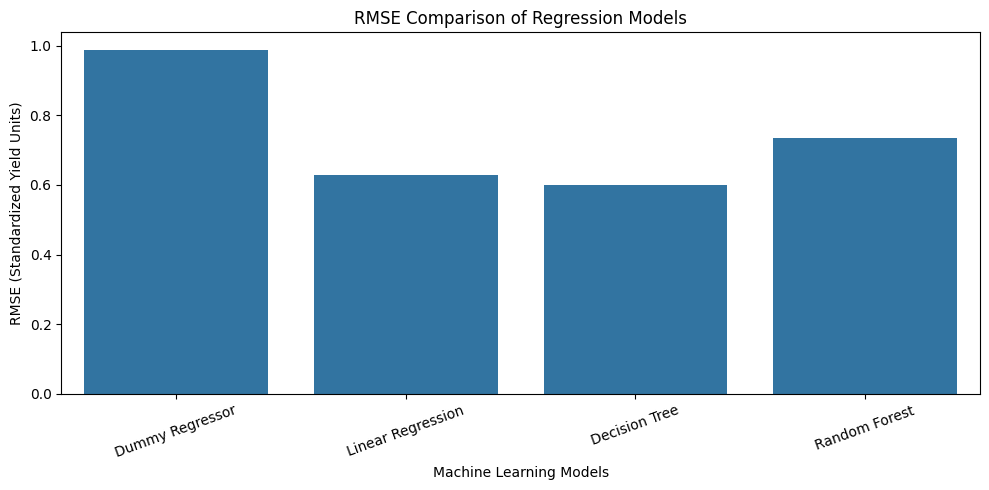

In [109]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results,
    x="Model",
    y="RMSE"
)

plt.title("RMSE Comparison of Regression Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("RMSE (Standardized Yield Units)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


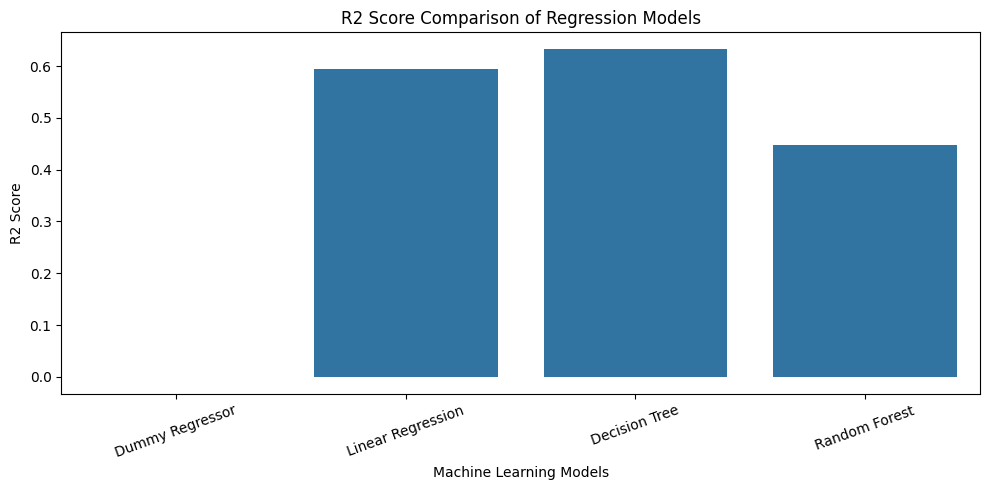

In [110]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results,
    x="Model",
    y="R2 Score"
)

plt.title("R2 Score Comparison of Regression Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("R2 Score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [111]:
from sklearn.model_selection import RandomizedSearchCV

# Define hyperparameter search space

param_grid = {
    "n_estimators": [50, 100, 150],
    "max_depth": [10, 15, 20, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", 0.5]
}

# Create Random Forest estimator

rf_tuning_model = RandomForestRegressor(
    random_state=42,
    n_jobs=2
)

# Configure randomized search

random_search = RandomizedSearchCV(
    estimator=rf_tuning_model,
    param_distributions=param_grid,
    n_iter=6,
    cv=3,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=2,
    verbose=1
)

# Fit using training data only

random_search.fit(X_train, y_train)

# Display best parameters

print("BEST HYPERPARAMETERS")
print(random_search.best_params_)

print("\nBest Cross-Validation RMSE:")
print(-random_search.best_score_)


Fitting 3 folds for each of 6 candidates, totalling 18 fits
BEST HYPERPARAMETERS
{'n_estimators': 50, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': None}

Best Cross-Validation RMSE:
0.5143147685341497


In [112]:
# Retrieve best model

best_rf_model = random_search.best_estimator_

# Generate predictions on test data

tuned_predictions = best_rf_model.predict(X_test)

# Calculate evaluation metrics

tuned_mae = mean_absolute_error(y_test, tuned_predictions)
tuned_mse = mean_squared_error(y_test, tuned_predictions)
tuned_rmse = np.sqrt(tuned_mse)
tuned_r2 = r2_score(y_test, tuned_predictions)

# Display results

print("TUNED RANDOM FOREST PERFORMANCE")
print("--------------------------------")
print("MAE:", tuned_mae)
print("MSE:", tuned_mse)
print("RMSE:", tuned_rmse)
print("R2 Score:", tuned_r2)


TUNED RANDOM FOREST PERFORMANCE
--------------------------------
MAE: 0.26321763189564135
MSE: 0.21082543363155123
RMSE: 0.45915730815435274
R2 Score: 0.7842633107902486


In [113]:
# Generate training predictions

train_predictions = best_rf_model.predict(X_train)

# Calculate training metrics

train_mae = mean_absolute_error(y_train, train_predictions)
train_rmse = np.sqrt(mean_squared_error(y_train, train_predictions))
train_r2 = r2_score(y_train, train_predictions)

# Calculate testing metrics

test_mae = mean_absolute_error(y_test, tuned_predictions)
test_rmse = np.sqrt(mean_squared_error(y_test, tuned_predictions))
test_r2 = r2_score(y_test, tuned_predictions)

# Create comparison table

overfitting_analysis = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2 Score"],
    "Training": [train_mae, train_rmse, train_r2],
    "Testing": [test_mae, test_rmse, test_r2]
})

display(overfitting_analysis.round(4))


,Metric,Training,Testing
0,MAE,0.2165,0.2632
1,RMSE,0.4126,0.4592
2,R2 Score,0.8307,0.7843


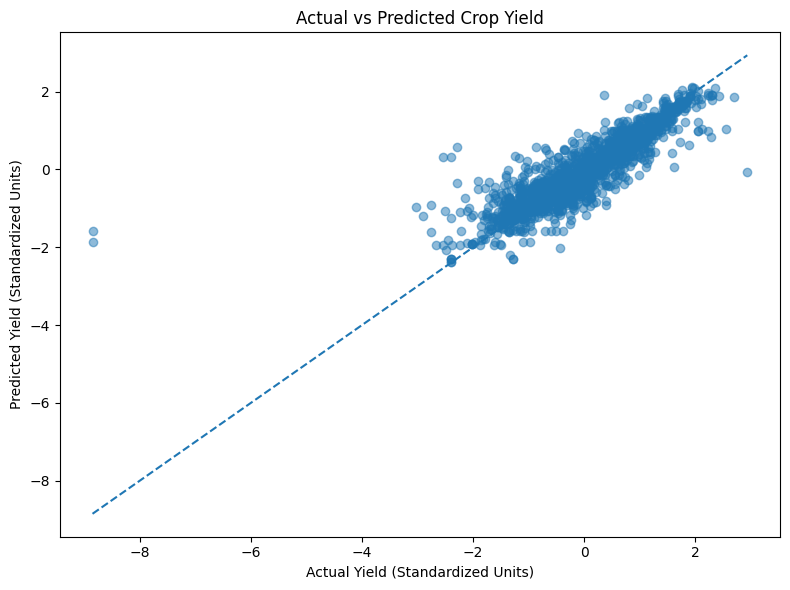

In [114]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    tuned_predictions,
    alpha=0.5
)

# Reference line

minimum = min(y_test.min(), tuned_predictions.min())
maximum = max(y_test.max(), tuned_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.title("Actual vs Predicted Crop Yield")
plt.xlabel("Actual Yield (Standardized Units)")
plt.ylabel("Predicted Yield (Standardized Units)")

plt.tight_layout()
plt.show()


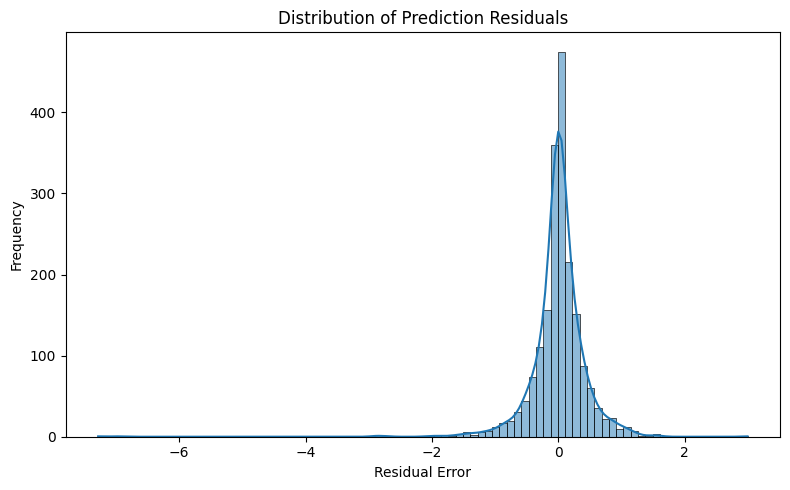

In [115]:
# Calculate residuals

residuals = y_test - tuned_predictions

# Plot residual distribution

plt.figure(figsize=(8, 5))

sns.histplot(
    residuals,
    kde=True
)

plt.title("Distribution of Prediction Residuals")
plt.xlabel("Residual Error")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


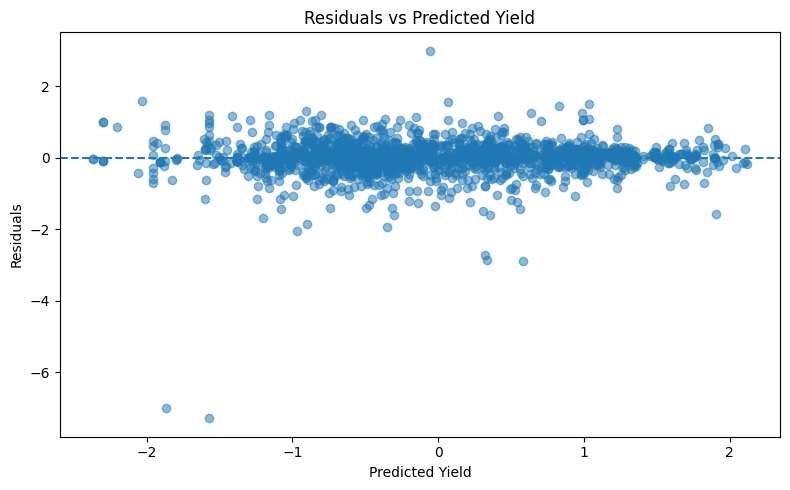

In [116]:
plt.figure(figsize=(8, 5))

plt.scatter(
    tuned_predictions,
    residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title("Residuals vs Predicted Yield")
plt.xlabel("Predicted Yield")
plt.ylabel("Residuals")

plt.tight_layout()
plt.show()


In [117]:
# Extract feature importance

importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_rf_model.feature_importances_
})

# Sort by importance

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 features

top_features = importance.head(15)

print("TOP 15 IMPORTANT FEATURES")

display(top_features)


TOP 15 IMPORTANT FEATURES


,Feature,Importance
759,Crop_Maize,0.223159
763,Crop_Rice,0.119671
760,Crop_Moong,0.081857
772,Area-2024-25,0.070353
768,Crop_Wheat,0.061090
767,Crop_Urad,0.046400
6,State_Chhattisgarh,0.026190
755,Crop_Barley,0.024920
17,State_Maharashtra,0.021228
769,Season_Kharif,0.020658


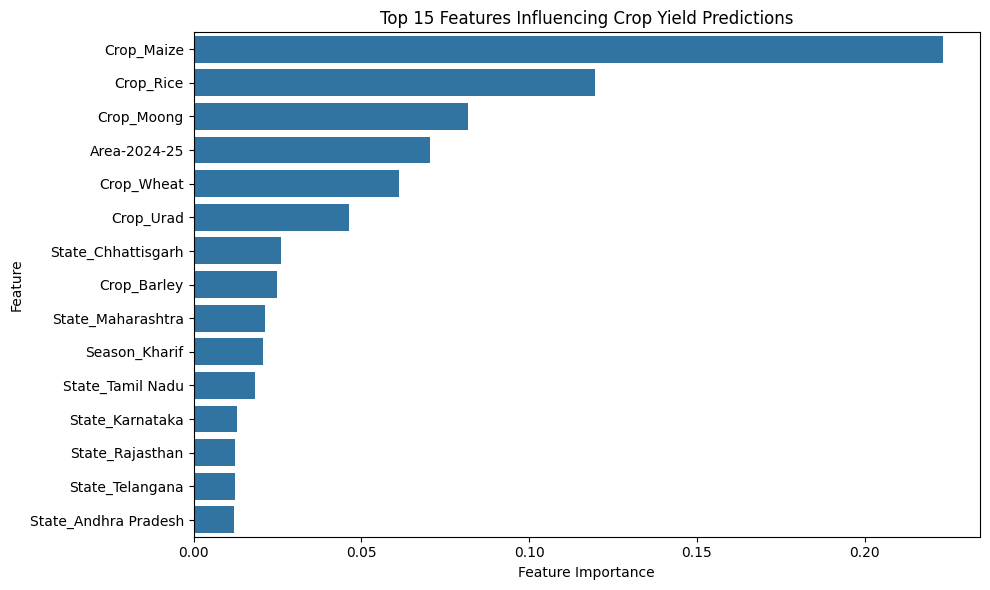

In [118]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features Influencing Crop Yield Predictions")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


In [119]:
# Create final comparison table

final_results = pd.DataFrame({
    "Model": [
        "Dummy Regressor",
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Tuned Random Forest"
    ],

    "MAE": [
        baseline_mae,
        linear_mae,
        tree_mae,
        rf_mae,
        tuned_mae
    ],

    "RMSE": [
        baseline_rmse,
        linear_rmse,
        tree_rmse,
        rf_rmse,
        tuned_rmse
    ],

    "R2 Score": [
        baseline_r2,
        linear_r2,
        tree_r2,
        rf_r2,
        tuned_r2
    ]
})

display(final_results.round(4))

# Identify lowest test RMSE

best_index = final_results["RMSE"].idxmin()

print("\nBest Model Based on Test RMSE:")
print(final_results.loc[best_index, "Model"])


,Model,MAE,RMSE,R2 Score
0,Dummy Regressor,0.7902,0.9891,-0.0010
1,Linear Regression,0.4308,0.6296,0.5944
2,Decision Tree,0.3870,0.5986,0.6333
3,Random Forest,0.5442,0.7352,0.4469
4,Tuned Random Forest,0.2632,0.4592,0.7843



Best Model Based on Test RMSE:
Tuned Random Forest


In [120]:
# Export model comparison results

final_results.to_csv(
    "Week3_Model_Comparison_Results.csv",
    index=False
)

# Export feature importance

importance.to_csv(
    "Week3_Feature_Importance.csv",
    index=False
)

# Export actual and predicted values

prediction_results = pd.DataFrame({
    "Actual_Yield": y_test.values,
    "Predicted_Yield": tuned_predictions
})

prediction_results.to_csv(
    "Week3_Prediction_Results.csv",
    index=False
)

print("Week 3 experimental results exported successfully!")


Week 3 experimental results exported successfully!
